### Exploration des données — Fiabilité des liaisons TGV

**Problématique :** Quelles sont les liaisons TGV les plus touchées par les retards à l'arrivée ?

**Objectif :** Analyser les taux de retard par liaison, leur évolution mensuelle et leur prévisibilité.

**Données :** [Régularité mensuelle TGV](https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/information/)

## 1. Importation des librairies

In [34]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

In [4]:
# Préalable
print("Python utilisé :", sys.executable)
print("Dossier de travail :", Path.cwd())
print("Fichiers CSV :", list(Path("../data/raw").glob("*.csv")))

Python utilisé : /home/emman/projets/RailInsight-SNCF/.venv/bin/python
Dossier de travail : /home/emman/projets/RailInsight-SNCF/notebooks
Fichiers CSV : [PosixPath('../data/raw/regularite-mensuelle-tgv-aqst.csv')]


## 2. Les données

In [11]:
# chargement de la base
df = pd.read_csv("../data/raw/regularite-mensuelle-tgv-aqst.csv", sep=";")
print("Lignes et colonnes :", df.shape)

Lignes et colonnes : (12907, 26)


In [12]:
# Structure générale du jeu de données
print("Dimensions :", df.shape)

print("\nInformations générales :")
df.info()

Dimensions : (12907, 26)

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64

## 3. Statistiques descriptives et couverture des données

In [16]:
# Statistiques descriptives des variables numériques
display(df.describe().T.round(2))

# Période couverte
print("Date minimale :", df["Date"].min())
print("Date maximale :", df["Date"].max())

# Répartition des observations par service
display(df["Service"].value_counts().to_frame("Nombre de lignes"))

,count,mean,std,min,25%,50%,75%,max
Durée moyenne du trajet,12907.0,170.69,87.73,0.00,99.00,163.00,223.00,786.00
Nombre de circulations prévues,12907.0,273.44,184.12,0.00,151.00,231.00,365.00,1104.00
Nombre de trains annulés,12907.0,8.27,21.81,0.00,0.00,2.00,7.00,297.00
Commentaire annulations,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard au départ,12907.0,86.70,88.75,0.00,22.00,52.00,127.00,598.00
Retard moyen des trains en retard au départ,12907.0,12.60,11.58,0.00,6.43,10.70,16.23,316.19
Retard moyen de tous les trains au départ,12907.0,3.22,5.02,-229.27,1.25,2.40,4.09,115.05
Commentaire retards au départ,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard à l'arrivée,12907.0,38.87,32.45,0.00,16.00,30.00,53.00,376.00
Retard moyen des trains en retard à l'arrivée,12907.0,35.62,15.61,-40.11,26.09,33.90,42.91,299.60


Date minimale : 2018-01
Date maximale : 2026-09


,Nombre de lignes
Service,
National,11339
International,1568


L'analyse descriptive porte sur 12 907 observations, réparties entre janvier 2018 et septembre 2026. Le service national est largement représenté avec 11 339 observations, contre 1 568 pour le service international. En moyenne, chaque observation compte 273 circulations prévues, dont environ 8 annulations et 39 trains en retard à l'arrivée. On observe également une forte variabilité entre les liaisons, notamment dans le nombre de circulations prévues, qui varie de 0 à 1 104. Ces premiers résultats montrent l'importance de tenir compte du volume de trains et de la période étudiée pour comparer correctement les taux de retard des différentes liaisons TGV.

## 4. Vérification de la qualité des données

In [19]:
# 1. Valeurs manquantes
manquants = pd.DataFrame({
    "Nombre": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2)
})

display(manquants[manquants["Nombre"] > 0])

,Nombre,Pourcentage (%)
Commentaire annulations,12907,100.00
Commentaire retards au départ,12907,100.00
Commentaire retards à l'arrivée,12209,94.59


In [20]:
# 2. Doublons
print("Doublons complets :", df.duplicated().sum())

cles = ["Date", "Service", "Gare de départ", "Gare d'arrivée"]
print("Doublons mois-service-liaison :", df.duplicated(subset=cles).sum())

Doublons complets : 0
Doublons mois-service-liaison : 0


In [21]:
# 3. Cohérence des effectifs
circules = df["Nombre de circulations prévues"] - df["Nombre de trains annulés"]

print("Annulations > trains prévus :",
      (df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]).sum())

print("Retards à l'arrivée > trains circulés :",
      (df["Nombre de trains en retard à l'arrivée"] > circules).sum())

print("Durées de trajet non positives :",
      (df["Durée moyenne du trajet"] <= 0).sum())

Annulations > trains prévus : 63
Retards à l'arrivée > trains circulés : 63
Durées de trajet non positives : 73


L'analyse de la qualité des données révèle que les valeurs manquantes concernent uniquement les trois variables de commentaires, dont deux sont entièrement vides et une présente 94,59 % de valeurs manquantes. Par ailleurs, aucun doublon n'a été détecté, que ce soit sur l'ensemble des variables ou sur la combinaison mois-service-liaison. Toutefois, les contrôles de cohérence mettent en évidence 63 observations où les annulations dépassent les circulations prévues, 63 où les retards à l'arrivée dépassent le nombre de trains circulés et 73 où la durée moyenne du trajet est nulle.

## 5. les anomalies

In [24]:
# Identification des observations présentant des anomalies
anomalie_annulation = (
    df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]
)

anomalie_retard = (
    df["Nombre de trains en retard à l'arrivée"] > circules
)

anomalie_duree = df["Durée moyenne du trajet"] <= 0

In [27]:
# Nombre d'observations concernées
anomalies = anomalie_annulation | anomalie_retard | anomalie_duree

print("Total de lignes présentant au moins une anomalie :", anomalies.sum())

Total de lignes présentant au moins une anomalie : 73


In [26]:
# Examination des observations concernées
colonnes = [
    "Date", "Service", "Gare de départ", "Gare d'arrivée",
    "Durée moyenne du trajet", "Nombre de circulations prévues",
    "Nombre de trains annulés", "Nombre de trains en retard à l'arrivée"
]

display(df.loc[anomalies, colonnes].head(10))

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard à l'arrivée
3406,2020-04,National,PARIS MONTPARNASSE,ST MALO,0,0,8,0
3407,2020-04,National,PARIS MONTPARNASSE,TOURS,0,0,9,0
3409,2020-04,National,NANTES,STRASBOURG,0,0,2,0
3411,2020-04,National,PARIS NORD,DOUAI,0,0,12,0
3412,2020-04,National,DUNKERQUE,PARIS NORD,0,0,15,0
3414,2020-04,National,MARSEILLE ST CHARLES,TOURCOING,0,0,1,0
3415,2020-04,National,LYON PART DIEU,MARNE LA VALLEE,0,0,19,0
3416,2020-04,National,MARNE LA VALLEE,MARSEILLE ST CHARLES,0,0,14,0
3417,2020-04,National,MARSEILLE ST CHARLES,MARNE LA VALLEE,0,0,13,0
3418,2020-04,National,PARIS LYON,AIX EN PROVENCE TGV,0,0,17,0


In [28]:
# Répartition des anomalies par mois
print(df.loc[anomalies, "Date"].value_counts().sort_index())

Date
2020-04    50
2020-05     9
2020-06     4
2020-08     2
2020-09     2
2020-10     2
2020-11     2
2020-12     2
Name: count, dtype: int64


Les 73 observations présentant des anomalies sont toutes concentrées en 2020, principalement en avril (50 observations), soit environ 68,5 % du total. Les anomalies diminuent fortement à partir de mai et deviennent ponctuelles jusqu'en décembre.


## 5. Analyse univariée des données

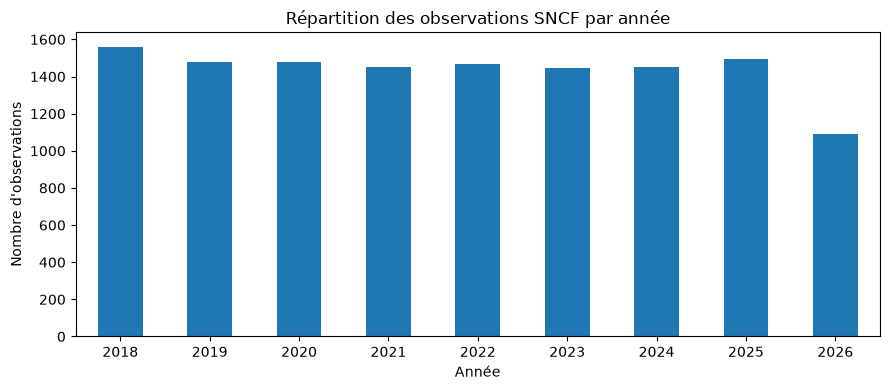

In [33]:
# Visualisation des observations par année

observations_annee.plot(
    kind="bar",
    figsize=(9, 4)
)

plt.title("Répartition des observations SNCF par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

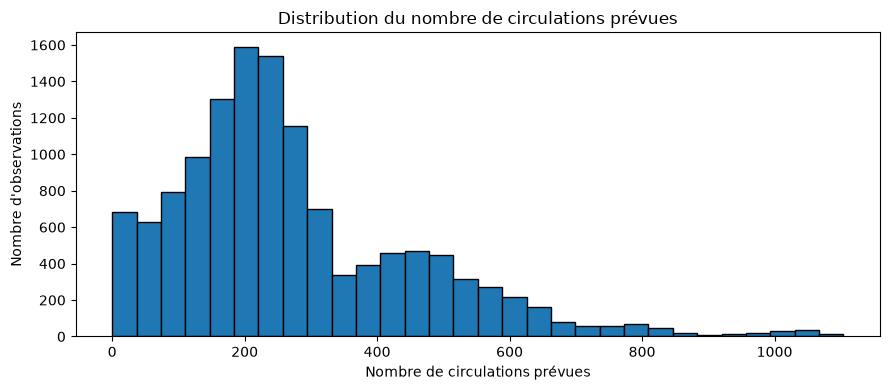

In [35]:
# Distribution des circulations prévues par liaison et par mois
df["Nombre de circulations prévues"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution du nombre de circulations prévues")
plt.xlabel("Nombre de circulations prévues")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

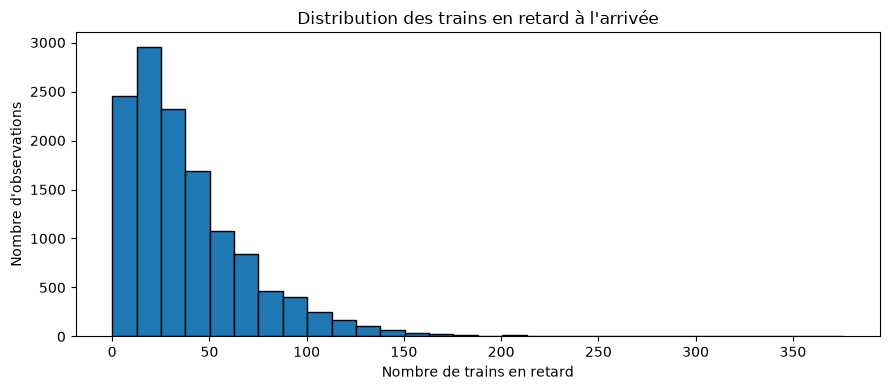

In [36]:
# Distribution du nombre de trains en retard à l'arrivée
df["Nombre de trains en retard à l'arrivée"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution des trains en retard à l'arrivée")
plt.xlabel("Nombre de trains en retard")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

La répartition annuelle des observations est relativement stable entre 2018 et 2025, tandis que 2026 est incomplète (données jusqu’en septembre). Les distributions des trains prévus et des retards à l’arrivée sont asymétriques à droite : la majorité des observations compte entre 150 et 300 trains prévus et entre 0 et 60 retards mensuels, avec quelques valeurs extrêmes. Ces disparités reflètent la nécessité de privilégier les taux de retard plutôt que les volumes absolus pour comparer leur régularité.

## 6 - Analyse bivariée

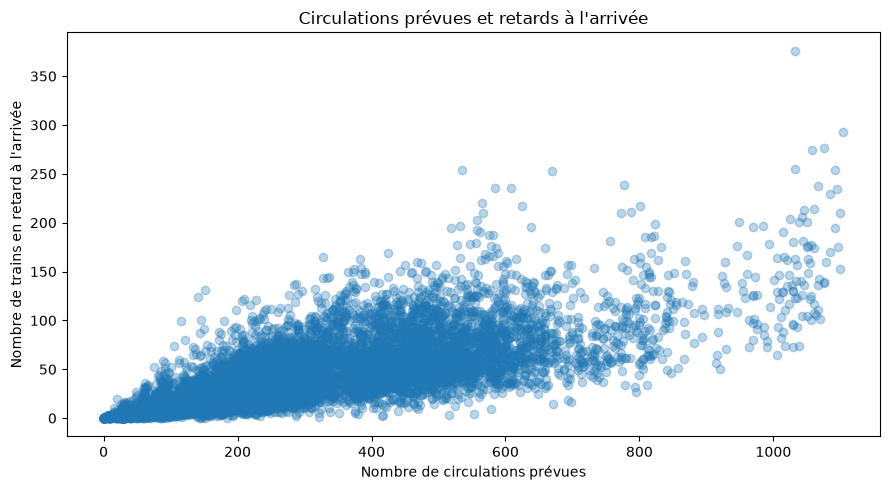

In [37]:
# Relation entre les circulations prévues et les retards à l'arrivée
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Nombre de circulations prévues"],
    df["Nombre de trains en retard à l'arrivée"],
    alpha=0.3
)

plt.title("Circulations prévues et retards à l'arrivée")
plt.xlabel("Nombre de circulations prévues")
plt.ylabel("Nombre de trains en retard à l'arrivée")
plt.tight_layout()
plt.show()

In [40]:
# Corrélation entre les circulations prévues et les retards à l'arrivée
x = df["Nombre de circulations prévues"]
y = df["Nombre de trains en retard à l'arrivée"]

print("Corrélation de Pearson :", round(x.corr(y, method="pearson"), 3))
print("Corrélation de Spearman :", round(x.corr(y, method="spearman"), 3))

Corrélation de Pearson : 0.758
Corrélation de Spearman : 0.804


Le nuage de points révèle une relation positive relativement forte entre le nombre de circulations prévues et le nombre de trains en retard à l'arrivée, confirmée par les coefficients de Pearson (0,758) et de Spearman (0,804). La dispersion augmente toutefois avec le volume de circulation. Cette association ne traduit pas nécessairement un lien de causalité : les liaisons les plus fréquentées enregistrent davantage de retards en valeur absolue, sans être forcément moins régulières.

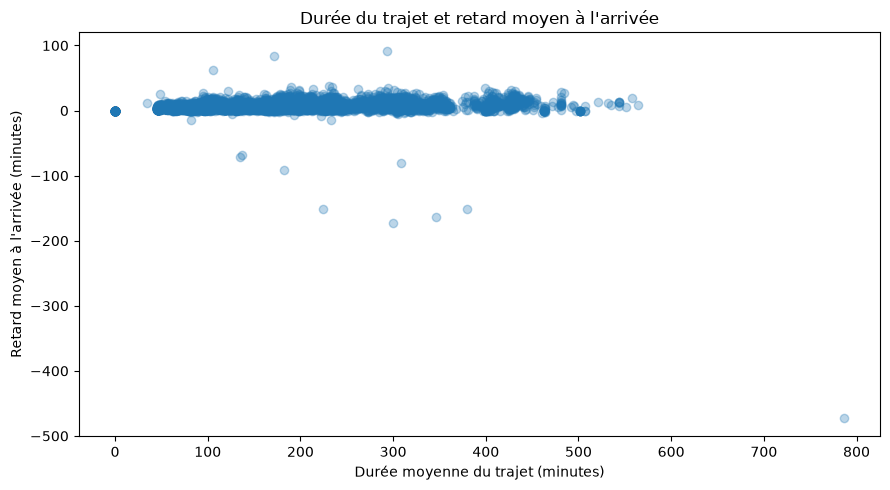

In [41]:
# Relation entre la durée du trajet et le retard moyen à l'arrivée
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Durée moyenne du trajet"],
    df["Retard moyen de tous les trains à l'arrivée"],
    alpha=0.3
)

plt.title("Durée du trajet et retard moyen à l'arrivée")
plt.xlabel("Durée moyenne du trajet (minutes)")
plt.ylabel("Retard moyen à l'arrivée (minutes)")
plt.tight_layout()
plt.show()

In [42]:
# Corrélations entre la durée du trajet et le retard moyen
x = df["Durée moyenne du trajet"]
y = df["Retard moyen de tous les trains à l'arrivée"]

print("Pearson :", round(x.corr(y, method="pearson"), 3))
print("Spearman :", round(x.corr(y, method="spearman"), 3))

Pearson : 0.171
Spearman : 0.383


Le nuage de points suggère une légère augmentation du retard moyen avec la durée du trajet, malgré une forte dispersion. Les corrélations de Pearson (0,171) et de Spearman (0,383) confirment une association positive limitée. Quelques valeurs extrêmes sont également observées.

Intensité des retards à l'arrivée

In [43]:
# Statistiques descriptives des retards selon leur gravité
colonnes_retard = [
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min"
]

display(df[colonnes_retard].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Nombre trains en retard > 15min,12907.0,28.10,23.91,0.0,11.0,22.0,38.0,312.0
Nombre trains en retard > 30min,12907.0,13.33,13.03,-44.0,4.0,10.0,18.0,202.0
Nombre trains en retard > 60min,12907.0,5.49,6.39,0.0,1.0,3.0,7.0,77.0


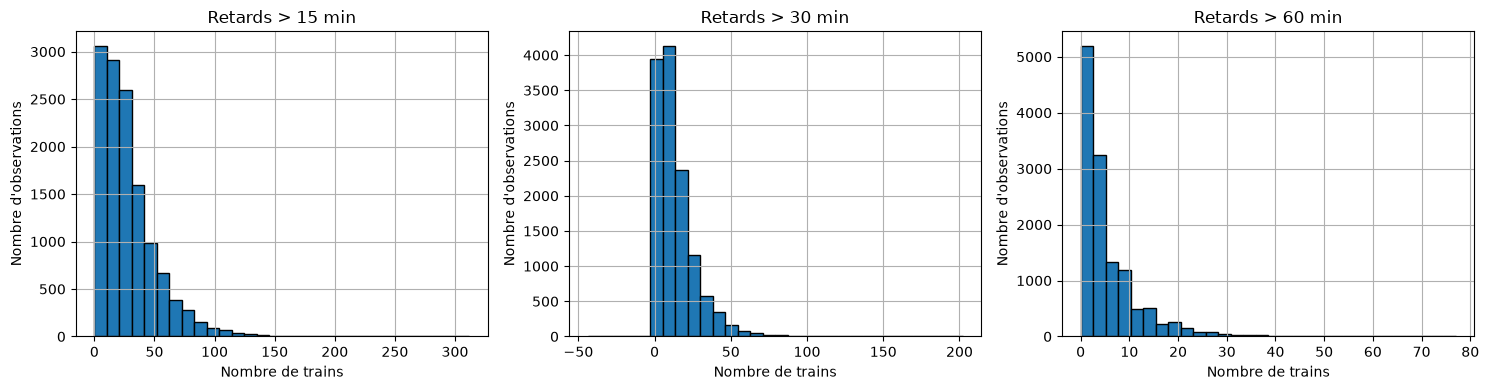

In [44]:
# Distribution des retards de plus de 15, 30 et 60 minutes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

seuils = [15, 30, 60]

for ax, colonne, seuil in zip(axes, colonnes_retard, seuils):
    df[colonne].hist(bins=30, ax=ax, edgecolor="black")
    ax.set_title(f"Retards > {seuil} min")
    ax.set_xlabel("Nombre de trains")
    ax.set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

In [45]:
# Corrélations entre les différents seuils de retard
display(df[colonnes_retard].corr(method="pearson").round(3))

,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
Nombre trains en retard > 15min,1.000,0.922,0.798
Nombre trains en retard > 30min,0.922,1.000,0.797
Nombre trains en retard > 60min,0.798,0.797,1.000


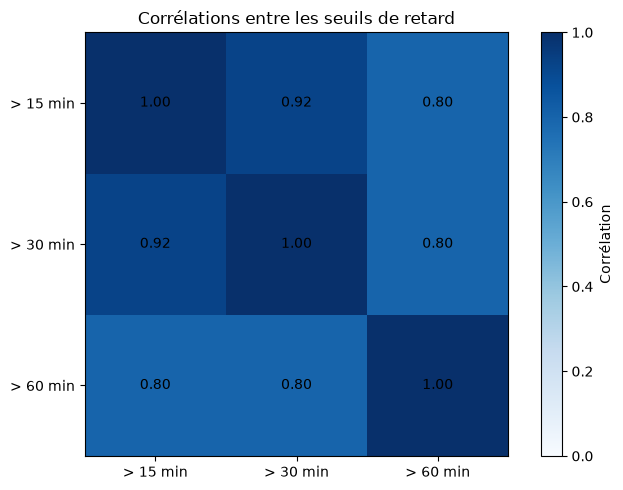

In [46]:
# Matrice de corrélation des retards selon leur gravité
correlations = df[colonnes_retard].corr()

plt.figure(figsize=(7, 5))
plt.imshow(correlations, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Corrélation")

plt.xticks(range(3), ["> 15 min", "> 30 min", "> 60 min"])
plt.yticks(range(3), ["> 15 min", "> 30 min", "> 60 min"])

for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{correlations.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Corrélations entre les seuils de retard")
plt.tight_layout()
plt.show()

L'analyse des retards à l'arrivée montre que leur fréquence diminue lorsque le seuil de retard augmente. En moyenne, on observe 28,10 trains ayant plus de 15 minutes de retard par liaison et par mois, contre 13,33 pour les retards de plus de 30 minutes et 5,49 pour ceux dépassant 60 minutes. Les distributions sont fortement asymétriques à droite, avec quelques observations présentant des retards particulièrement élevés. Par ailleurs, les corrélations entre les différents seuils sont fortes, notamment entre les retards de plus de 15 et 30 minutes (0,922).

## 6. Choisir une probl?matique
| Question simple | Variables | Int?r?t | Limite |
|---|---|---|---|
| Quelles liaisons ont le plus de retards ? | Gares, mois, trains pr?vus, annul?s et en retard | Facile ? comprendre et utile pour comparer | Comparer la m?me p?riode et tenir compte des volumes et des seuils de retard |
| Y a-t-il plus de retards ? certaines p?riodes ? | Mois, liaison, taux de retard | Plusieurs ann?es disponibles | Les liaisons pr?sentes changent ; une variation ne prouve pas une saisonnalit? |
| Les causes de retard diff?rent-elles selon le service ? | Service, pourcentages de causes | Cat?gories d?j? pr?sentes | Certaines sommes sont incoh?rentes ; le sens des pourcentages doit ?tre confirm? |

**Question recommand?e : quelles liaisons ont le plus de retards ?**
Les variables n?cessaires sont pr?sentes. On pourra comparer les liaisons sur une m?me ann?e compl?te, en montrant aussi le nombre de trains. Ce classement reste ? r?aliser.


## 7. Synth?se pour la r?union
- **Donn?es :** 12 907 lignes et 26 variables, de janvier 2018 ? septembre 2026.
- **Constat :** le taux m?dian de retard est de **13.36 %** sur les lignes retenues. Ce n'est pas un taux national.
- **Qualit? :** aucun doublon ; deux colonnes de commentaires enti?rement vides. 63 lignes ont plus d'annulations que de trains pr?vus ; 282 ont une somme des causes ?loign?e de 100 %. Pour le calcul du taux, 73 lignes sont ?cart?es.
- **Choix :** comparer les retards par liaison sur une p?riode commune.
- **Limites :** donn?es mensuelles, seuil de retard variable, couverture diff?rente selon les liaisons.

Les chiffres ci-dessus sont calcul?s sur les donn?es t?l?charg?es. Les graphiques ne prouvent pas les raisons des retards ni une saisonnalit?.

**Suite possible, sans l'impl?menter ici :** v?rifier les anomalies, choisir une ann?e compl?te et comparer les liaisons avec leurs volumes de trains.

Toutes les cellules de code ont ?t? ex?cut?es. Aucun mod?le entra?n? ; donn?es brutes inchang?es.
